# Tamil Uyir Ezhuthukkal (12 vowels): Forger vs Detector
**Conditional DCGAN at 128×128 (spectral norm, hinge loss, projection detector, DiffAugment, EMA) + ResNet-18 recogniser**

Runtime → Change runtime type → **GPU**, then Runtime → **Run all**. Every figure, the GIF, the metrics and the
model weights are written to `uyir_outputs/` and zipped at the end.

| Stage | What happens |
|---|---|
| 1 | Download the HP Labs India handwritten Tamil characters (through the TamilNet repo), keep the 12 vowels, and check the folder → letter map against the dataset's own label file |
| 2 | Normalise every glyph: crop, keep the aspect ratio, thin to a skeleton, redraw with one stroke width, centre on 128×128 |
| 3 | Stratified 60 % train / 40 % test split. The forger and detector only ever see the 60 % |
| 4 | Train the **forger** (generator) against the **detector** (discriminator) |
| 5 | Train the **recogniser** (ResNet-18) on real letters only |
| 6 | Judge the forger: does the recogniser read the forged letters as the intended vowel? Fréchet distance, memorisation check |
| 7 | Ablation: recogniser trained on real + forged letters vs. real only, both scored once on the untouched 40 % |
| 8 | Final showcase: forged letters, the detector's verdicts, one "writer" across all 12 letters, latent walk, training GIF |

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ============================================================== 0. SETUP
import os, sys, csv, json, math, time, copy, random, shutil, hashlib, zipfile, subprocess, warnings, contextlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
SMOKE = os.environ.get("UYIR_SMOKE") == "1"   # tiny run, only used to test the code on a CPU


def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return r.returncode, (r.stdout + r.stderr).strip()


if IN_COLAB:
    sh("apt-get -qq install -y fonts-lohit-taml > /dev/null 2>&1")

import numpy as np
import cv2
import matplotlib
if not IN_COLAB and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from PIL import Image, ImageDraw
from scipy import linalg
from skimage.morphology import skeletonize
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.utils import make_grid

warnings.filterwarnings("ignore", message=".*does not support Tamil.*")
warnings.filterwarnings("ignore", message="Glyph .* missing from font")
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step\\(\\)`")

# Tamil-capable font with Latin fallback (fixes the "Glyph missing" warnings of the old script)
TAMIL_FONT = None
for _p in sorted(fm.findSystemFonts()):
    if "tamil" in os.path.basename(_p).lower():
        fm.fontManager.addfont(_p)
        TAMIL_FONT = fm.FontProperties(fname=_p).get_name()
        break
plt.rcParams["font.family"] = ["DejaVu Sans"] + ([TAMIL_FONT] if TAMIL_FONT else [])
INLINE = "inline" in matplotlib.get_backend().lower()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
print(f"torch {torch.__version__} | device: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}"
      f" | Tamil font: {TAMIL_FONT or 'not found (romanised labels)'}")

torch 2.14.1+cu130 | device: Tesla T4 | Tamil font: Lohit Tamil


In [ ]:
# ============================================================== 1. SETTINGS  (the only cell you normally edit)
PRESET = "standard"          # "quick" | "standard" | "best"  (the GAN cell prints its own time estimate)
SPLIT_MODE = "random_60_40"  # "random_60_40" = stratified 60/40 | "official" = HP Labs competition test set (~66/34)
ARCH = "resnet"              # "resnet" = residual DCGAN (best quality) | "dcgan" = classic all-conv DCGAN layout
SAVE_TO_DRIVE = False        # True keeps outputs + GAN checkpoints in Google Drive (survives a Colab disconnect)
RESUME_GAN = True            # continue from the last GAN checkpoint when one exists
EXTRA_SOURCES = {}           # optional extra *handwritten* folders you have checked: {"/content/x/folder_1": "அ", ...}

PRESETS = {
    "quick":    dict(gan_iters=3000,  cls_epochs=8,  seeds=1, synth_per_class=150),
    "standard": dict(gan_iters=10000, cls_epochs=15, seeds=1, synth_per_class=150),
    "best":     dict(gan_iters=20000, cls_epochs=20, seeds=3, synth_per_class=200),
}
CFG = dict(PRESETS[PRESET])
CFG.update(
    img_size=128, stroke_px=5, glyph_box=0.80, seed=42, max_per_class=None,
    # forger (G) / detector (D)
    z_dim=120, g_ch=32, d_ch=32, gan_batch=64, lr_g=1e-4, lr_d=4e-4, betas=(0.0, 0.99), d_steps=1,
    diffaug="translation,cutout", ema_decay=0.999, gan_amp=True, mode_seeking=1.0,
    # recogniser
    cls_batch=64, cls_lr=5e-4, cls_wd=0.02, label_smoothing=0.05,
)
if SMOKE:
    _e = lambda k, d: type(d)(os.environ.get(k, d))
    CFG.update(gan_iters=_e("UYIR_ITERS", 40), gan_batch=_e("UYIR_BATCH", 8), cls_epochs=_e("UYIR_EPOCHS", 1),
               seeds=1, synth_per_class=_e("UYIR_SYNTH", 8), max_per_class=_e("UYIR_MAXPC", 40),
               img_size=_e("UYIR_SIZE", 128), cls_batch=_e("UYIR_CLSBATCH", 32), stroke_px=_e("UYIR_STROKE", 5))
    ARCH = os.environ.get("UYIR_ARCH", ARCH)
    SPLIT_MODE = os.environ.get("UYIR_SPLIT", SPLIT_MODE)

BASE = Path("/content") if IN_COLAB else Path(os.environ.get("UYIR_BASE", ".")).resolve()
DATA_DIR = BASE / "uyir_data"
if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/uyir_outputs")
else:
    OUT = BASE / "uyir_outputs"
for d in (DATA_DIR, OUT, OUT / "evolution"):
    d.mkdir(parents=True, exist_ok=True)

UYIR = ['அ', 'ஆ', 'இ', 'ஈ', 'உ', 'ஊ', 'எ', 'ஏ', 'ஐ', 'ஒ', 'ஓ', 'ஔ']
ROMAN = ['a', 'aa', 'i', 'ii', 'u', 'uu', 'e', 'ee', 'ai', 'o', 'oo', 'au']
N_CLS = len(UYIR)
# HP Labs / TamilNet class folder for each vowel.
# Folder 11 is ஃ (aytham), NOT ஔ. ஔ lives in folder 155. The old script trained "ஔ" on aytham images.
HPL_FOLDER = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 155]
IMG = CFG["img_size"]


def label(i, roman=True):
    return (f"{UYIR[i]} {ROMAN[i]}" if roman else UYIR[i]) if TAMIL_FONT else ROMAN[i]


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def finish(fig, fname):
    fig.savefig(OUT / fname, dpi=150, bbox_inches="tight", facecolor="white")
    if INLINE:
        plt.show()
    plt.close(fig)


def letter_grid(imgs, title, fname, col_titles=None, row_titles=None, cell=0.85, title_size=13):
    """imgs: uint8 [rows, cols, H, W] with white ink on black; drawn as dark ink on paper."""
    r, c = imgs.shape[:2]
    fig, axes = plt.subplots(r, c, figsize=(c * cell + (0.8 if row_titles else 0), r * cell + 0.7), squeeze=False)
    for i in range(r):
        for j in range(c):
            ax = axes[i, j]
            ax.imshow(imgs[i, j], cmap="gray_r", vmin=0, vmax=255, interpolation="lanczos")
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_color("#dddddd")
            if i == 0 and col_titles is not None:
                ax.set_title(col_titles[j], fontsize=12)
            if j == 0 and row_titles is not None:
                ax.set_ylabel(row_titles[i], fontsize=9, rotation=0, ha="right", va="center", labelpad=8)
    fig.suptitle(title, fontsize=title_size)
    fig.tight_layout()
    finish(fig, fname)


seed_all(CFG["seed"])
print(f"Preset '{PRESET}' | split {SPLIT_MODE} | arch {ARCH} | outputs -> {OUT}")

Preset 'standard' | split random_60_40 | arch resnet | outputs -> /content/uyir_outputs


## Stage 1 — Data
**Source:** HP Labs India isolated handwritten Tamil characters (IWFHR-2006), as packaged in
[ganeshmm/TamilNet](https://github.com/ganeshmm/TamilNet): about 500 samples per letter from native writers.
Only the 12 vowel folders are downloaded (sparse checkout, a few seconds instead of 238,000 files).

Sources from the original script that were dropped, and why:
* **sasicodes/tamily-1** (Hugging Face) is synthetic *printed* text lines (≈121 GB). Cropping the first letter of a
  printed phrase does not give handwritten vowels, and the old call also failed because the dataset needs a config name.
* **Mendeley b7vhz7z83k** is a palm-leaf character set from 20 centuries with 1,045 labels; its folder numbers are not
  the 12 modern vowels, so the old "folders 1–12 → vowels" guess would have injected wrong labels.
* **Mendeley 6zcpgchvmx** (SASTRA students' handwriting) is usable, but its folder → letter map has to be checked by
  eye first. Download it from Mendeley, unzip it, run `peek_folders("/content/<unzipped folder>")`, then list the
  vowel folders in `EXTRA_SOURCES`.
* The THPLMD palm-leaf paper (Data in Brief 2024) and the CICT digital archive have page/line-level manuscripts,
  not labelled character images.

In [ ]:
# ============================================================== 1. DATA
TAMILNET = DATA_DIR / "TamilNet"
IMG_EXT = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}


def fetch_tamilnet():
    csv_path = TAMILNET / "data" / "TamilChar.csv"
    if csv_path.exists() and all((TAMILNET / "data" / "processed" / "train" / str(f)).exists() for f in HPL_FOLDER):
        return
    shutil.rmtree(TAMILNET, ignore_errors=True)
    wanted = ["/data/TamilChar.csv"] + [f"/data/processed/{s}/{f}/" for s in ("train", "test") for f in HPL_FOLDER]
    print("Downloading the 12 vowel folders from github.com/ganeshmm/TamilNet (sparse checkout)...")
    rc, out = sh(f"git clone -q --depth 1 --filter=blob:none --sparse https://github.com/ganeshmm/TamilNet.git '{TAMILNET}'")
    if rc == 0:
        rc, out = sh(f"cd '{TAMILNET}' && git sparse-checkout set --no-cone " + " ".join(f"'{w}'" for w in wanted))
    if rc != 0 or not csv_path.exists():
        print("Sparse checkout failed, doing a full clone instead (slower).", out[-300:])
        shutil.rmtree(TAMILNET, ignore_errors=True)
        rc, out = sh(f"git clone -q --depth 1 https://github.com/ganeshmm/TamilNet.git '{TAMILNET}'")
        assert rc == 0, out


def peek_folders(root, max_folders=60):
    """Show one image from each sub-folder so you can tell which folders hold which letter (for EXTRA_SOURCES)."""
    subs = sorted([p for p in Path(root).iterdir() if p.is_dir()], key=lambda p: (len(p.name), p.name))[:max_folders]
    cols = 10
    rows = math.ceil(len(subs) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.1, rows * 1.3), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, d in zip(axes.flat, subs):
        files = [p for p in sorted(d.rglob("*")) if p.suffix.lower() in IMG_EXT]
        if files:
            ax.imshow(Image.open(files[0]).convert("L"), cmap="gray")
        ax.set_title(d.name, fontsize=8)
    fig.tight_layout()
    finish(fig, "peek_folders.png")


fetch_tamilnet()

# Check the folder -> letter map against the dataset's own label file, so a wrong map cannot slip in again
with open(TAMILNET / "data" / "TamilChar.csv", encoding="utf-8") as f:
    _rows = [r for r in csv.reader(f) if r and r[0].strip().isdigit()]
_code = {int(r[0]): r[2].split()[0] for r in _rows}
for v, folder in enumerate(HPL_FOLDER):
    got = chr(int(_code[folder], 16))
    assert got == UYIR[v], f"TamilNet folder {folder} holds '{got}', expected '{UYIR[v]}'"
print(f"Label map checked against TamilChar.csv. Folder 11 is '{chr(int(_code[11], 16))}' (aytham) -> excluded; "
      f"ஔ comes from folder 155.")

items = []   # (path, label, origin)
for v, folder in enumerate(HPL_FOLDER):
    for part in ("train", "test"):
        d = TAMILNET / "data" / "processed" / part / str(folder)
        items += [(str(p), v, f"hpl_{part}") for p in sorted(d.iterdir()) if p.suffix.lower() in IMG_EXT]
for folder, letter in EXTRA_SOURCES.items():
    assert letter in UYIR, f"{letter} is not one of the 12 uyir letters"
    items += [(str(p), UYIR.index(letter), "extra") for p in sorted(Path(folder).rglob("*")) if p.suffix.lower() in IMG_EXT]

if CFG["max_per_class"]:
    rng = random.Random(0)
    keep = []
    for v in range(N_CLS):
        cls_items = [it for it in items if it[1] == v]
        rng.shuffle(cls_items)
        keep += cls_items[:CFG["max_per_class"]]
    items = keep
print(f"{len(items)} handwritten vowel images found")

Label map checked against TamilChar.csv. Folder 11 is 'ஃ' (aytham) -> excluded; ஔ comes from folder 155.
6190 handwritten vowel images found


## Stage 2 — Glyph normalisation
The old segmentation stretched any image smaller than 128 px to a square (distorting the letter), and the HP Labs
strokes are 1–2 px pen traces that break up when resized. Here every glyph is cropped, scaled with its aspect ratio
kept, thinned to a skeleton and redrawn with one stroke width, then centred on a 128×128 canvas.
One consistent stroke style makes the forger's job much easier and the letters look cleaner.

  1000/6190 glyphs normalised
  2000/6190 glyphs normalised
  3000/6190 glyphs normalised
  4000/6190 glyphs normalised
  5000/6190 glyphs normalised
  6000/6190 glyphs normalised
Normalised 6190 glyphs in 12s


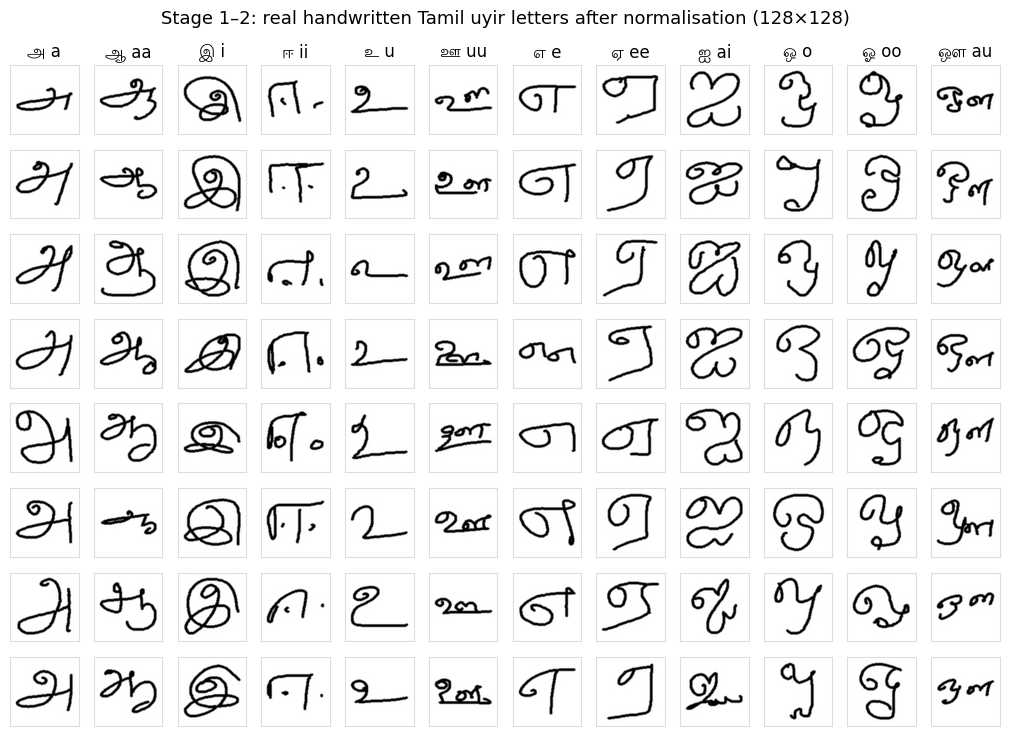

In [ ]:
# ============================================================== 2. GLYPH NORMALISATION


def normalize_glyph(gray, size=128, box_frac=0.80, stroke_px=5, blur_sigma=0.8):
    g = np.asarray(gray, dtype=np.uint8)
    if g.mean() > 127:                                  # make ink white on black
        g = 255 - g
    _, bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    n, lab, st, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)
    if n > 1:                                           # drop only specks; keeps the dot of ஈ
        ink = st[1:, cv2.CC_STAT_AREA].sum()
        keep = np.zeros(n, bool)
        keep[1:] = st[1:, cv2.CC_STAT_AREA] >= max(2, 0.002 * ink)
        bw = np.where(keep[lab], 255, 0).astype(np.uint8)
    ys, xs = np.nonzero(bw)
    if len(xs) == 0:
        return np.zeros((size, size), np.uint8)
    crop = bw[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = crop.shape
    s = (size * box_frac) / max(h, w)                   # longest side -> 80 % of the canvas, aspect ratio kept
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = cv2.resize(crop, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
    skel = skeletonize(small > 40).astype(np.uint8) * 255
    pad = stroke_px
    tmp = np.zeros((nh + 2 * pad, nw + 2 * pad), np.uint8)
    tmp[pad:pad + nh, pad:pad + nw] = skel
    thick = cv2.dilate(tmp, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (stroke_px, stroke_px)))
    th, tw = thick.shape
    out = np.zeros((size, size), np.uint8)
    y0, x0 = (size - th) // 2, (size - tw) // 2
    sy, sx = max(0, -y0), max(0, -x0)
    y0, x0 = max(0, y0), max(0, x0)
    hh, ww = min(th - sy, size - y0), min(tw - sx, size - x0)
    out[y0:y0 + hh, x0:x0 + ww] = thick[sy:sy + hh, sx:sx + ww]
    return cv2.GaussianBlur(out, (0, 0), blur_sigma) if blur_sigma > 0 else out


_key = hashlib.md5(("|".join(p for p, _, _ in items) + f"{IMG}-{CFG['stroke_px']}-{CFG['glyph_box']}").encode()).hexdigest()[:10]
cache = DATA_DIR / f"glyphs_{IMG}_{_key}.npz"
if cache.exists():
    z = np.load(cache, allow_pickle=False)
    X_all, y_all, origin = z["X"], z["y"], z["origin"]
    print(f"Loaded {len(X_all)} normalised glyphs from cache")
else:
    t0 = time.time()
    X_all = np.zeros((len(items), IMG, IMG), np.uint8)
    for i, (p, _, _) in enumerate(items):
        X_all[i] = normalize_glyph(Image.open(p).convert("L"), IMG, CFG["glyph_box"], CFG["stroke_px"])
        if (i + 1) % 1000 == 0:
            print(f"  {i + 1}/{len(items)} glyphs normalised")
    y_all = np.array([v for _, v, _ in items], np.int64)
    origin = np.array([o for _, _, o in items])
    np.savez_compressed(cache, X=X_all, y=y_all, origin=origin)
    print(f"Normalised {len(X_all)} glyphs in {time.time() - t0:.0f}s")

_rng = np.random.default_rng(0)
_k = 8
preview = np.stack([X_all[_rng.choice(np.where(y_all == v)[0], _k, replace=False)] for v in range(N_CLS)], 1)
letter_grid(preview, "Stage 1–2: real handwritten Tamil uyir letters after normalisation (128×128)",
            "01_real_letters.png", col_titles=[label(i) for i in range(N_CLS)])

## Stage 3 — Split
Stratified 60 % / 40 %. The 40 % test letters are never shown to the forger, the detector or the recogniser
during training, and the recogniser is scored on them once, at the final epoch (the old script picked its "peak"
epoch by looking at the test set, which inflates the number).

Note: a random split puts letters from the same writers in both halves. `SPLIT_MODE = "official"` uses the HP Labs
competition test set instead (≈66/34), which is the harder, more honest setting.

In [ ]:
# ============================================================== 3. SPLIT
if SPLIT_MODE == "official":
    tr_idx = np.where(origin != "hpl_test")[0]
    te_idx = np.where(origin == "hpl_test")[0]
else:
    tr_idx, te_idx = train_test_split(np.arange(len(y_all)), train_size=0.60, test_size=0.40,
                                      stratify=y_all, random_state=CFG["seed"])
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_te, y_te = X_all[te_idx], y_all[te_idx]
print(f"Split ({SPLIT_MODE}): total {len(y_all)} | train {len(y_tr)} ({100 * len(y_tr) / len(y_all):.0f}%) | "
      f"test {len(y_te)} ({100 * len(y_te) / len(y_all):.0f}%)")
print("per class train/test:", " ".join(f"{ROMAN[v]}:{(y_tr == v).sum()}/{(y_te == v).sum()}" for v in range(N_CLS)))

Split (random_60_40): total 6190 | train 3714 (60%) | test 2476 (40%)
per class train/test: a:317/212 aa:314/209 i:314/209 ii:305/204 u:311/207 uu:315/210 e:308/206 ee:314/209 ai:307/205 o:301/200 oo:298/199 au:310/206


## Stage 4 — Forger vs Detector (conditional DCGAN)
Why the old GAN produced poor letters, and what replaces it:

| Problem in the old GAN | Fix here |
|---|---|
| ~1,400 updates in total (12 epochs × 116 batches): far too short for 128×128 | 10,000 updates (standard preset), with checkpoints so a disconnect does not lose the run |
| Detector overpowered the forger (D loss ≈ 0.2, G loss jumping 2 → 10) | Spectral normalisation on every detector layer + hinge loss + two learning rates (D 4e-4, G 1e-4) |
| Only ~3,700 training letters, so the detector memorises them | DiffAugment (random shift + cut-out applied to real *and* forged letters before the detector) |
| Class label only concatenated to the noise; AC-GAN head tends to collapse variety | Class-conditional batch-norm in every forger block + projection detector |
| The forger can ignore its noise and draw one fixed letter per class (mode collapse) | The noise z is split across every forger layer (BigGAN "skip-z") + a mode-seeking loss (MSGAN) that penalises two different z giving the same letter |
| Transposed convolutions leave checkerboard artefacts | Nearest-neighbour upsample + 3×3 convolution |
| Samples taken from the raw, noisy forger weights | Exponential moving average (EMA) of the forger weights, batch-norm statistics re-estimated before sampling |

`ARCH = "dcgan"` keeps the classic DCGAN shape (one conv per stage, strided-conv detector) with all the same fixes;
`"resnet"` adds residual connections, which gives smoother strokes at 128×128.

In [ ]:
# ============================================================== 4. FORGER (G) AND DETECTOR (D)
SN = nn.utils.parametrizations.spectral_norm


def _init(m):
    nn.init.xavier_uniform_(m.weight)
    if getattr(m, "bias", None) is not None:
        nn.init.zeros_(m.bias)
    return m


def sn(m):
    return SN(_init(m))


class CondBN(nn.Module):
    """Batch-norm whose scale and shift come from (letter embedding, slice of z)."""
    def __init__(self, ch, cond_dim):
        super().__init__()
        self.bn = nn.BatchNorm2d(ch, affine=False)
        self.gain, self.bias = nn.Linear(cond_dim, ch), nn.Linear(cond_dim, ch)
        for m in (self.gain, self.bias):
            nn.init.normal_(m.weight, 0.0, 0.02); nn.init.zeros_(m.bias)

    def forward(self, x, c):
        return self.bn(x) * (1 + self.gain(c))[:, :, None, None] + self.bias(c)[:, :, None, None]


class GResBlock(nn.Module):
    def __init__(self, cin, cout, cond_dim):
        super().__init__()
        self.bn1, self.bn2 = CondBN(cin, cond_dim), CondBN(cout, cond_dim)
        self.c1, self.c2 = _init(nn.Conv2d(cin, cout, 3, 1, 1)), _init(nn.Conv2d(cout, cout, 3, 1, 1))
        self.skip = _init(nn.Conv2d(cin, cout, 1))

    def forward(self, x, c):
        h = F.interpolate(F.relu(self.bn1(x, c)), scale_factor=2, mode="nearest")
        h = self.c2(F.relu(self.bn2(self.c1(h), c)))
        return h + self.skip(F.interpolate(x, scale_factor=2, mode="nearest"))


class GConvBlock(nn.Module):
    """Classic DCGAN stage, with resize-conv instead of a transposed conv."""
    def __init__(self, cin, cout, cond_dim):
        super().__init__()
        self.c, self.bn = _init(nn.Conv2d(cin, cout, 3, 1, 1)), CondBN(cout, cond_dim)

    def forward(self, x, c):
        return F.relu(self.bn(self.c(F.interpolate(x, scale_factor=2, mode="nearest")), c))


class Forger(nn.Module):
    """Generator: noise z + letter id -> 128x128 handwritten letter in [-1, 1].
    z is split into one slice per stage (BigGAN "skip-z"), so the noise reaches every layer and cannot be ignored."""
    def __init__(self, n_cls, img_size=128, z_dim=120, ch=32, arch="resnet", emb_dim=128):
        super().__init__()
        n_up = int(math.log2(img_size)) - 2
        assert z_dim % (n_up + 1) == 0, f"z_dim must split into {n_up + 1} equal slices"
        chs = [max(ch * 16 // 2 ** i, 16) for i in range(n_up + 1)]   # 512@4 -> 256@8 -> ... -> 16@128
        self.arch, self.c0, self.zc = arch, chs[0], z_dim // (n_up + 1)
        cond = emb_dim + self.zc
        self.shared = nn.Embedding(n_cls, emb_dim)
        self.fc = _init(nn.Linear(self.zc + emb_dim, 16 * chs[0]))
        block = GResBlock if arch == "resnet" else GConvBlock
        self.in_bn = CondBN(chs[0], cond) if arch != "resnet" else None
        self.blocks = nn.ModuleList([block(chs[i], chs[i + 1], cond) for i in range(n_up)])
        self.out_bn = nn.BatchNorm2d(chs[-1]) if arch == "resnet" else None
        self.out = _init(nn.Conv2d(chs[-1], 1, 3, 1, 1))

    def forward(self, z, y):
        zs = torch.split(z, self.zc, dim=1)
        e = self.shared(y)
        h = self.fc(torch.cat([zs[0], e], 1)).view(-1, self.c0, 4, 4)
        if self.in_bn is not None:
            h = F.relu(self.in_bn(h, torch.cat([e, zs[0]], 1)))
        for b, zc in zip(self.blocks, zs[1:]):
            h = b(h, torch.cat([e, zc], 1))
        if self.out_bn is not None:
            h = F.relu(self.out_bn(h))
        return torch.tanh(self.out(h))


class DResBlock(nn.Module):
    def __init__(self, cin, cout, down=True, first=False):
        super().__init__()
        self.c1, self.c2 = sn(nn.Conv2d(cin, cout, 3, 1, 1)), sn(nn.Conv2d(cout, cout, 3, 1, 1))
        self.skip = sn(nn.Conv2d(cin, cout, 1)) if (cin != cout or down) else None
        self.down, self.first = down, first

    def forward(self, x):
        h = self.c2(F.relu(self.c1(x if self.first else F.relu(x))))
        if self.down:
            h = F.avg_pool2d(h, 2)
        s = x
        if self.first and self.down:
            s = F.avg_pool2d(s, 2)
        if self.skip is not None:
            s = self.skip(s)
        if self.down and not self.first:
            s = F.avg_pool2d(s, 2)
        return h + s


class Detector(nn.Module):
    """Discriminator with spectral norm and a class projection: real-vs-forged score for (image, letter)."""
    def __init__(self, n_cls, img_size=128, ch=32, arch="resnet"):
        super().__init__()
        n_down = int(math.log2(img_size)) - 2
        chs = [min(ch * 2 ** i, 512) for i in range(n_down)]          # 32@64 -> 64@32 -> ... -> 512@4
        layers = []
        if arch == "resnet":
            layers.append(DResBlock(1, chs[0], down=True, first=True))
            layers += [DResBlock(chs[i - 1], chs[i], down=True) for i in range(1, n_down)]
            layers += [DResBlock(chs[-1], chs[-1], down=False), nn.ReLU()]
        else:
            cin = 1
            for c in chs:
                layers += [sn(nn.Conv2d(cin, c, 3, 1, 1)), nn.LeakyReLU(0.1),
                           sn(nn.Conv2d(c, c, 4, 2, 1)), nn.LeakyReLU(0.1)]
                cin = c
            layers += [sn(nn.Conv2d(cin, cin, 3, 1, 1)), nn.LeakyReLU(0.1)]
        self.body = nn.Sequential(*layers)
        self.fc = sn(nn.Linear(chs[-1], 1))
        self.proj = sn(nn.Embedding(n_cls, chs[-1]))

    def forward(self, x, y):
        h = self.body(x).sum(dim=(2, 3))
        return self.fc(h).squeeze(1) + (self.proj(y) * h).sum(1)


# ---- DiffAugment (Zhao et al., 2020): same random shift + cut-out for real and forged letters, detector side only
def _translate(x, ratio=0.125):
    B, C, H, W = x.shape
    sh_, sw_ = int(H * ratio + 0.5), int(W * ratio + 0.5)
    tx = torch.randint(-sh_, sh_ + 1, (B, 1, 1), device=x.device)
    ty = torch.randint(-sw_, sw_ + 1, (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(H, device=x.device),
                                torch.arange(W, device=x.device), indexing="ij")
    gx = torch.clamp(gx + tx + 1, 0, H + 1)
    gy = torch.clamp(gy + ty + 1, 0, W + 1)
    xp = F.pad(x, [1, 1, 1, 1], value=-1.0)            # pad with background, not grey
    return xp.permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2)


def _cutout(x, ratio=0.3):
    B, C, H, W = x.shape
    ch_, cw_ = int(H * ratio + 0.5), int(W * ratio + 0.5)
    ox = torch.randint(0, H + (1 - ch_ % 2), (B, 1, 1), device=x.device)
    oy = torch.randint(0, W + (1 - cw_ % 2), (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(ch_, device=x.device),
                                torch.arange(cw_, device=x.device), indexing="ij")
    gx = torch.clamp(gx + ox - ch_ // 2, 0, H - 1)
    gy = torch.clamp(gy + oy - cw_ // 2, 0, W - 1)
    mask = torch.ones(B, H, W, dtype=x.dtype, device=x.device)
    mask[gb, gx, gy] = 0
    mask = mask.unsqueeze(1)
    return x * mask - (1 - mask)                       # cut region becomes background (-1)


def diff_augment(x):
    if "translation" in CFG["diffaug"]:
        x = _translate(x)
    if "cutout" in CFG["diffaug"]:
        x = _cutout(x)
    return x.contiguous()


@torch.no_grad()
def ema_update(ema, model, decay):
    for pe, p in zip(ema.parameters(), model.parameters()):
        pe.lerp_(p.detach(), 1 - decay)
    for be, b in zip(ema.buffers(), model.buffers()):
        be.copy_(b)


@torch.no_grad()
def recalibrate_bn(g, n_batches=50, bs=100):
    """Re-estimate batch-norm statistics for the EMA forger ("standing statistics") before sampling."""
    bns = [m for m in g.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]
    for m in bns:
        m.reset_running_stats(); m.momentum = None
    g.train()
    for _ in range(n_batches):
        g(torch.randn(bs, CFG["z_dim"], device=DEVICE), torch.randint(0, N_CLS, (bs,), device=DEVICE))
    for m in bns:
        m.momentum = 0.1
    g.eval()


@torch.no_grad()
def forge(g, labels, z=None, bs=200):
    """Letters from the forger as uint8 [N, H, W] (white ink on black)."""
    labels = torch.as_tensor(np.asarray(labels)).long()
    z = torch.randn(len(labels), CFG["z_dim"]) if z is None else z.cpu()
    out = []
    for i in range(0, len(labels), bs):
        x = g(z[i:i + bs].to(DEVICE), labels[i:i + bs].to(DEVICE)).float()
        out.append(((x[:, 0] + 1) * 127.5).clamp(0, 255).round().byte().cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def detector_scores(d, X, y, bs=200):
    d.eval()
    s = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE).unsqueeze(1).float().div(127.5).sub(1)
        s.append(d(xb, torch.from_numpy(np.asarray(y[i:i + bs])).long().to(DEVICE)).float().cpu())
    d.train()
    return torch.cat(s).numpy()


def to_grid(x_uint8, nrow):
    t = torch.from_numpy(x_uint8).unsqueeze(1).float() / 255
    return (make_grid(t, nrow=nrow, padding=2, pad_value=0.0)[0].numpy() * 255).astype(np.uint8)


G = Forger(N_CLS, IMG, CFG["z_dim"], CFG["g_ch"], ARCH).to(DEVICE)
D = Detector(N_CLS, IMG, CFG["d_ch"], ARCH).to(DEVICE)
print(f"Forger: {sum(p.numel() for p in G.parameters()) / 1e6:.2f}M params | "
      f"Detector: {sum(p.numel() for p in D.parameters()) / 1e6:.2f}M params")

Forger: 4.20M params | Detector: 9.61M params


In [ ]:
# ============================================================== 4b. TRAIN THE FORGER AGAINST THE DETECTOR
G_ema = copy.deepcopy(G).eval()
for p in G_ema.parameters():
    p.requires_grad_(False)
opt_g = torch.optim.Adam(G.parameters(), lr=CFG["lr_g"], betas=CFG["betas"])
opt_d = torch.optim.Adam(D.parameters(), lr=CFG["lr_d"], betas=CFG["betas"])
use_amp = CFG["gan_amp"] and DEVICE.type == "cuda"
scaler_g = torch.amp.GradScaler("cuda", enabled=use_amp)
scaler_d = torch.amp.GradScaler("cuda", enabled=use_amp)


def autocast():
    return torch.autocast("cuda", dtype=torch.float16) if use_amp else contextlib.nullcontext()


X_gan = torch.from_numpy(X_tr).to(DEVICE)
y_gan = torch.from_numpy(y_tr).long().to(DEVICE)


def real_pair_diversity(X, y, n=300, seed=0):
    """Same quantity the mode-seeking term measures, for two real letters of the same class (z distance = E|z1-z2|)."""
    rng = np.random.default_rng(seed)
    vals = []
    for v in range(N_CLS):
        idx = np.where(y == v)[0]
        a, b = rng.choice(idx, n), rng.choice(idx, n)
        vals.append(np.abs(X[a].astype(np.float32) - X[b].astype(np.float32)).mean() / 127.5)
    return float(np.mean(vals)) / (2 / math.sqrt(math.pi))


# Mode-seeking only pushes while the forger is LESS varied than real handwriting (90 % of the real level);
# above that it switches off, so it cannot trade letter quality for extra randomness.
DIV_TARGET = 0.9 * real_pair_diversity(X_tr, y_tr)


def real_batch(b):
    idx = torch.randint(0, len(X_gan), (b,), device=DEVICE)
    return X_gan[idx].unsqueeze(1).float().div(127.5).sub(1), y_gan[idx]


TOTAL, B = CFG["gan_iters"], CFG["gan_batch"]
SNAP_EVERY = max(TOTAL // 40, 10)
LOG_EVERY = 20
CKPT_EVERY = 1000
fixed_z = torch.randn(8 * N_CLS, CFG["z_dim"], generator=torch.Generator().manual_seed(123)).to(DEVICE)
fixed_y = torch.arange(N_CLS).repeat(8).to(DEVICE)       # each grid row = the 12 letters
hist = {k: [] for k in ("it", "loss_d", "loss_g", "d_real", "d_fake", "diversity")}
sig = {k: CFG[k] for k in ("img_size", "z_dim", "g_ch", "d_ch", "stroke_px", "seed", "diffaug")}
sig.update(arch=ARCH, split=SPLIT_MODE, n_train=int(len(y_tr)))
ckpt_path = OUT / f"gan_checkpoint_{ARCH}_{IMG}.pt"
start = 0


def save_ckpt(it):
    torch.save(dict(sig=sig, it=it, G=G.state_dict(), D=D.state_dict(), G_ema=G_ema.state_dict(),
                    opt_g=opt_g.state_dict(), opt_d=opt_d.state_dict(), hist=hist), ckpt_path)


if RESUME_GAN and ckpt_path.exists():
    ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    if ck["sig"] == sig:
        G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"]); G_ema.load_state_dict(ck["G_ema"])
        opt_g.load_state_dict(ck["opt_g"]); opt_d.load_state_dict(ck["opt_d"])
        hist, start = ck["hist"], ck["it"]
        print(f"Resuming the GAN from iteration {start}")
    else:
        print("A checkpoint exists but for different settings; starting fresh.")
if start == 0:
    for f in (OUT / "evolution").glob("*.npz"):
        f.unlink()

print(f"Training forger vs detector for {TOTAL} iterations (batch {B}, AMP {'on' if use_amp else 'off'}); "
      f"diversity floor for mode-seeking = {DIV_TARGET:.3f}")
acc = torch.zeros(5, device=DEVICE)
n_acc, bad_logs, t0, t_mark = 0, 0, time.time(), None
for it in range(start, TOTAL):
    if it == start + 50:
        t_mark = time.time()
    # ---- detector step: real letters should score >= +1, forged letters <= -1 (hinge loss)
    for _ in range(CFG["d_steps"]):
        xr, yr = real_batch(B)
        with torch.no_grad(), autocast():
            xf = G(torch.randn(B, CFG["z_dim"], device=DEVICE), yr)
        with autocast():
            d_real = D(diff_augment(xr), yr)
            d_fake = D(diff_augment(xf), yr)
            loss_d = F.relu(1 - d_real).mean() + F.relu(1 + d_fake).mean()
        opt_d.zero_grad(set_to_none=True)
        scaler_d.scale(loss_d).backward()
        scaler_d.step(opt_d); scaler_d.update()
    # ---- forger step: make the detector score forged letters as real,
    #      + mode-seeking term: two different z for the same letter must give two different letters
    D.requires_grad_(False)
    half = B // 2
    yh = torch.randint(0, N_CLS, (half,), device=DEVICE)
    yg = torch.cat([yh, yh])
    zg = torch.randn(2 * half, CFG["z_dim"], device=DEVICE)
    with autocast():
        xg = G(zg, yg)
        loss_adv = -D(diff_augment(xg), yg).mean()
    xg32 = xg.float()
    diversity = (xg32[:half] - xg32[half:]).abs().mean() / (zg[:half] - zg[half:]).abs().mean()
    if CFG["mode_seeking"] > 0:
        loss_g = loss_adv.float() + CFG["mode_seeking"] / (torch.clamp(diversity, max=DIV_TARGET) + 1e-5)
    else:
        loss_g = loss_adv.float()
    opt_g.zero_grad(set_to_none=True)
    scaler_g.scale(loss_g).backward()
    scaler_g.step(opt_g); scaler_g.update()
    D.requires_grad_(True)
    ema_update(G_ema, G, min(CFG["ema_decay"], (1 + it) / (10 + it)))

    acc += torch.stack([loss_d.detach().float(), loss_adv.detach().float(),
                        d_real.detach().float().mean(), d_fake.detach().float().mean(), diversity.detach()])
    n_acc += 1
    if (it + 1) % LOG_EVERY == 0 or it + 1 == TOTAL:
        vals = (acc / n_acc).tolist()
        acc.zero_(); n_acc = 0
        if all(math.isfinite(v) for v in vals):
            for k, v in zip(("loss_d", "loss_g", "d_real", "d_fake", "diversity"), vals):
                hist[k].append(v)
            hist["it"].append(it + 1)
            bad_logs = 0
        else:
            bad_logs += 1
            if use_amp and bad_logs >= 3:
                print("Non-finite losses under mixed precision; switching AMP off and continuing.")
                use_amp = False
                scaler_g = torch.amp.GradScaler("cuda", enabled=False)
                scaler_d = torch.amp.GradScaler("cuda", enabled=False)
    if it + 1 == start + 150 and t_mark is not None:
        spi = (time.time() - t_mark) / 100
        print(f"  ~{spi:.3f} s/iteration -> about {spi * (TOTAL - it - 1) / 60:.0f} more minutes for the GAN")
    if (it + 1) % SNAP_EVERY == 0 or it == start or it + 1 == TOTAL:
        with torch.no_grad():
            G_ema.train()
            snap = G_ema(fixed_z, fixed_y).float()
            G_ema.eval()
        np.savez_compressed(OUT / "evolution" / f"{it + 1:06d}.npz",
                            x=((snap[:, 0] + 1) * 127.5).clamp(0, 255).round().byte().cpu().numpy())
    if (it + 1) % 500 == 0 or it + 1 == TOTAL:
        h = {k: hist[k][-1] for k in ("loss_d", "loss_g", "d_real", "d_fake", "diversity")} if hist["it"] else {}
        print(f"  iter {it + 1:6d}/{TOTAL} | D loss {h.get('loss_d', float('nan')):.3f} | G loss {h.get('loss_g', float('nan')):.3f}"
              f" | D(real) {h.get('d_real', float('nan')):+.2f} | D(forged) {h.get('d_fake', float('nan')):+.2f}"
              f" | diversity {h.get('diversity', float('nan')):.3f} | {(time.time() - t0) / 60:.1f} min")
    if (it + 1) % CKPT_EVERY == 0 or it + 1 == TOTAL:
        save_ckpt(it + 1)

# Final forger = EMA weights with re-estimated batch-norm statistics
G_star = copy.deepcopy(G_ema)
recalibrate_bn(G_star, n_batches=8 if SMOKE else 50)
D.eval()
torch.save(G_star.state_dict(), OUT / "forger_G_ema.pt")
torch.save(D.state_dict(), OUT / "detector_D.pt")
print(f"GAN done in {(time.time() - t0) / 60:.1f} min. Weights saved to {OUT}")

Training forger vs detector for 10000 iterations (batch 64, AMP on); diversity floor for mode-seeking = 0.237
  ~0.283 s/iteration -> about 46 more minutes for the GAN
  iter    500/10000 | D loss 1.206 | G loss 0.701 | D(real) +0.76 | D(forged) -0.61 | diversity 0.244 | 2.6 min
  iter   1000/10000 | D loss 1.061 | G loss 0.842 | D(real) +0.82 | D(forged) -0.71 | diversity 0.245 | 5.0 min
  iter   1500/10000 | D loss 1.215 | G loss 0.722 | D(real) +0.80 | D(forged) -0.54 | diversity 0.255 | 7.5 min
  iter   2000/10000 | D loss 1.098 | G loss 0.846 | D(real) +0.74 | D(forged) -0.78 | diversity 0.255 | 10.0 min
  iter   2500/10000 | D loss 1.002 | G loss 0.904 | D(real) +0.97 | D(forged) -0.74 | diversity 0.246 | 12.5 min
  iter   3000/10000 | D loss 0.531 | G loss 1.527 | D(real) +1.44 | D(forged) -1.42 | diversity 0.245 | 14.9 min
  iter   3500/10000 | D loss 0.480 | G loss 1.575 | D(real) +1.85 | D(forged) -1.55 | diversity 0.249 | 17.4 min
  iter   4000/10000 | D loss 0.910 | G loss 

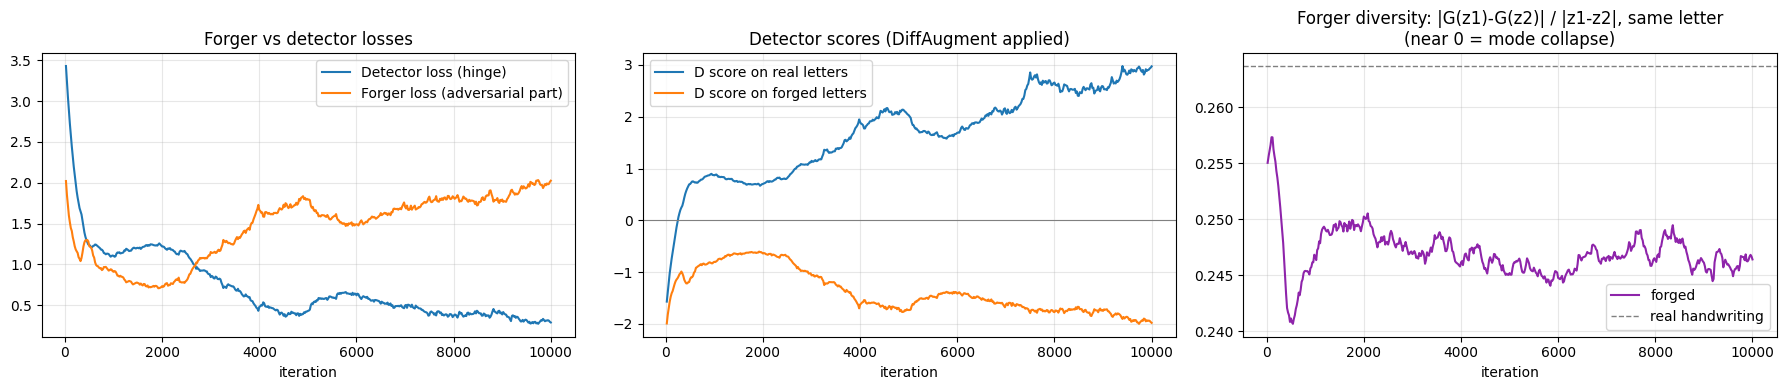

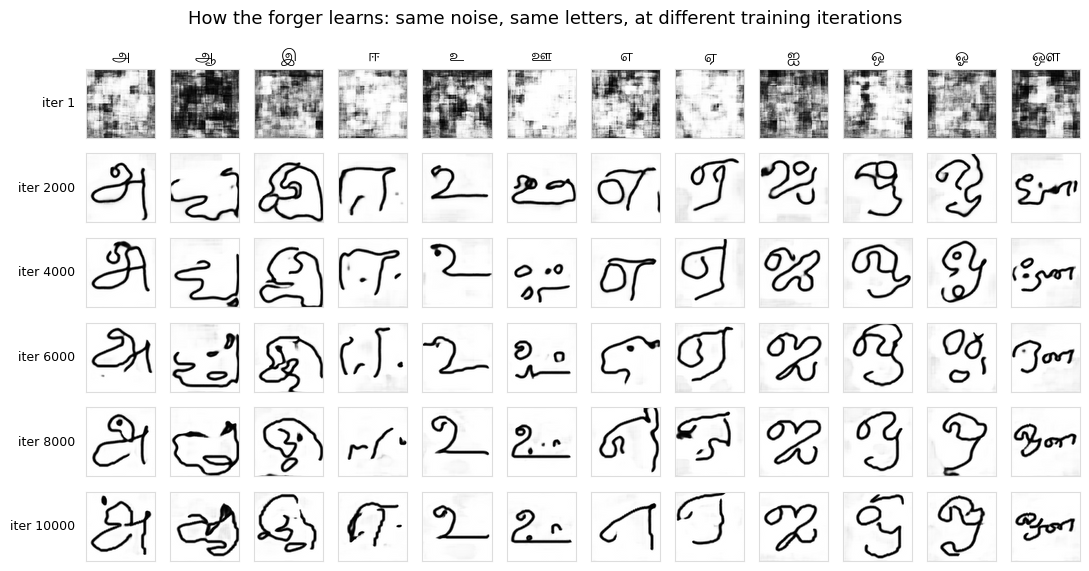

Saved 41 evolution frames -> 03_forger_evolution.gif


In [ ]:
# ============================================================== 4c. GAN TRAINING CURVES + EVOLUTION GIF


def smooth(v, a=0.9):
    out, m = [], None
    for x in v:
        m = x if m is None else a * m + (1 - a) * x
        out.append(m)
    return out


if hist["it"]:
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].plot(hist["it"], smooth(hist["loss_d"]), label="Detector loss (hinge)")
    ax[0].plot(hist["it"], smooth(hist["loss_g"]), label="Forger loss (adversarial part)")
    ax[0].set_xlabel("iteration"); ax[0].set_title("Forger vs detector losses"); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(hist["it"], smooth(hist["d_real"]), label="D score on real letters")
    ax[1].plot(hist["it"], smooth(hist["d_fake"]), label="D score on forged letters")
    ax[1].axhline(0, color="grey", lw=0.8)
    ax[1].set_xlabel("iteration"); ax[1].set_title("Detector scores (DiffAugment applied)"); ax[1].legend(); ax[1].grid(alpha=0.3)
    ax[2].plot(hist["it"], smooth(hist["diversity"]), color="#8e24aa", label="forged")
    ax[2].axhline(DIV_TARGET / 0.9, color="grey", ls="--", lw=1, label="real handwriting")
    ax[2].legend()
    ax[2].set_xlabel("iteration"); ax[2].grid(alpha=0.3)
    ax[2].set_title("Forger diversity: |G(z1)-G(z2)| / |z1-z2|, same letter\n(near 0 = mode collapse)")
    fig.tight_layout()
    finish(fig, "02_gan_training_curves.png")

snaps = sorted((OUT / "evolution").glob("*.npz"))
frames = []
for s in snaps:
    grid = 255 - to_grid(np.load(s)["x"], nrow=N_CLS)                 # dark ink on white paper
    im = Image.fromarray(grid).convert("RGB")
    canvas = Image.new("RGB", (im.width, im.height + 28), "white")
    canvas.paste(im, (0, 28))
    ImageDraw.Draw(canvas).text((8, 6), f"iteration {int(s.stem)}", fill=(0, 0, 0))
    frames.append(canvas)
if frames:
    frames[0].save(OUT / "03_forger_evolution.gif", save_all=True, append_images=frames[1:] + [frames[-1]] * 8,
                   duration=180, loop=0)
    pick = [snaps[i] for i in np.unique(np.linspace(0, len(snaps) - 1, min(6, len(snaps))).round().astype(int))]
    strip = np.stack([np.load(s)["x"][:N_CLS] for s in pick])        # first row of the fixed grid
    letter_grid(strip, "How the forger learns: same noise, same letters, at different training iterations",
                "03_forger_evolution_strip.png", col_titles=[label(i, False) for i in range(N_CLS)],
                row_titles=[f"iter {int(s.stem)}" for s in pick])
print(f"Saved {len(frames)} evolution frames -> 03_forger_evolution.gif")

## Stage 5 — Recogniser (ResNet-18), real letters only
ImageNet ResNet-18 with a one-channel stem: the pretrained 7×7 RGB filters are summed into one grey filter
(the old script squashed them to 3×3, which throws the pretrained filters away), stride-2 stem kept and the max-pool
removed so thin strokes survive. Augmentation is a random small rotation/shear/scale/shift done on the GPU.
The model kept is the one from the **last** epoch: no checkpoint is chosen by looking at the test set.

In [ ]:
# ============================================================== 5. RECOGNISER


class Recogniser(nn.Module):
    def __init__(self, n_cls=12):
        super().__init__()
        try:
            m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
        except Exception as e:                       # no internet for the weights: train from scratch
            print("Could not load ImageNet weights, training from scratch:", str(e)[:80])
            m = torchvision.models.resnet18(weights=None)
        w = m.conv1.weight.detach().sum(1, keepdim=True)
        m.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)
        with torch.no_grad():
            m.conv1.weight.copy_(w)
        m.maxpool = nn.Identity()
        m.fc = nn.Identity()
        self.backbone = m
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(512, n_cls))

    def features(self, x):
        return self.backbone(x)

    def forward(self, x):
        return self.head(self.features(x))


def random_affine(x, deg=10, translate=0.06, scale=(0.9, 1.1), shear=8):
    """Per-sample random rotation / shear / scale / shift on the GPU. x in [0, 1], background 0."""
    b, dev = x.size(0), x.device
    a = torch.empty(b, device=dev).uniform_(-deg, deg) * math.pi / 180
    shr = torch.tan(torch.empty(b, device=dev).uniform_(-shear, shear) * math.pi / 180)
    s = torch.empty(b, device=dev).uniform_(*scale)
    t = torch.empty(b, 2, device=dev).uniform_(-translate, translate) * 2
    cos, sin = torch.cos(a), torch.sin(a)
    theta = torch.stack([torch.stack([cos, cos * shr - sin, t[:, 0]], 1),
                         torch.stack([sin, sin * shr + cos, t[:, 1]], 1)], 1)
    theta[:, :, :2] = theta[:, :, :2] / s.view(b, 1, 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)


def _prep(xb_uint8):
    return xb_uint8.unsqueeze(1).float().div(255)


@torch.no_grad()
def predict(model, X, bs=256, feats=False):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        xb = _prep(torch.from_numpy(X[i:i + bs]).to(DEVICE)).sub(0.5).div(0.5)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            o = model.features(xb) if feats else model(xb)
        out.append(o.float().cpu())
    return torch.cat(out).numpy()


def train_recogniser(X, y, epochs, seed, tag):
    seed_all(seed)
    model = Recogniser(N_CLS).to(DEVICE)
    bs = CFG["cls_batch"]
    steps = max(1, len(X) // bs)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["cls_lr"], weight_decay=CFG["cls_wd"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["cls_lr"], total_steps=epochs * steps, pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    Xg, yg = torch.from_numpy(X).to(DEVICE), torch.from_numpy(y).long().to(DEVICE)
    h = {"train_acc": [], "test_acc": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X), device=DEVICE)
        correct = torch.zeros((), device=DEVICE)
        for k in range(steps):
            idx = perm[k * bs:(k + 1) * bs]
            xb = random_affine(_prep(Xg[idx])).sub(0.5).div(0.5)
            yb = yg[idx]
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                logits = model(xb)
                loss = F.cross_entropy(logits, yb, label_smoothing=CFG["label_smoothing"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            correct += (logits.argmax(1) == yb).sum()
        tr_acc = 100 * correct.item() / (steps * bs)
        te_acc = 100 * (predict(model, X_te).argmax(1) == y_te).mean()     # learning curve only, not used to pick a model
        h["train_acc"].append(tr_acc); h["test_acc"].append(te_acc)
        print(f"  [{tag} seed {seed}] epoch {ep + 1:2d}/{epochs} | train acc {tr_acc:6.2f}% | test acc {te_acc:6.2f}%")
    return model, h


def evaluate(model):
    pred = predict(model, X_te).argmax(1)
    return dict(acc=100 * float((pred == y_te).mean()), macro_f1=100 * float(f1_score(y_te, pred, average="macro"))), pred


SEEDS = [CFG["seed"] + s for s in range(CFG["seeds"])]
runs = {"real": [], "real+forged": []}
print("Training the recogniser on REAL letters only")
t0 = time.time()
model_real, hist_real = train_recogniser(X_tr, y_tr, CFG["cls_epochs"], SEEDS[0], "real")
m, pred_real = evaluate(model_real)
runs["real"].append(m)
torch.save(model_real.state_dict(), OUT / "recogniser_real_only.pt")
print(f"Real-only recogniser: test accuracy {m['acc']:.2f}% | macro-F1 {m['macro_f1']:.2f}% "
      f"({(time.time() - t0) / 60:.1f} min)")

Training the recogniser on REAL letters only
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]


  [real seed 42] epoch  1/15 | train acc  72.01% | test acc  97.01%
  [real seed 42] epoch  2/15 | train acc  97.49% | test acc  95.11%
  [real seed 42] epoch  3/15 | train acc  98.55% | test acc  96.97%
  [real seed 42] epoch  4/15 | train acc  98.60% | test acc  97.70%
  [real seed 42] epoch  5/15 | train acc  98.95% | test acc  97.62%
  [real seed 42] epoch  6/15 | train acc  99.38% | test acc  97.78%
  [real seed 42] epoch  7/15 | train acc  99.41% | test acc  98.02%
  [real seed 42] epoch  8/15 | train acc  99.62% | test acc  98.30%
  [real seed 42] epoch  9/15 | train acc  99.78% | test acc  98.18%
  [real seed 42] epoch 10/15 | train acc  99.84% | test acc  98.18%
  [real seed 42] epoch 11/15 | train acc  99.87% | test acc  98.26%
  [real seed 42] epoch 12/15 | train acc 100.00% | test acc  98.26%
  [real seed 42] epoch 13/15 | train acc  99.97% | test acc  98.26%
  [real seed 42] epoch 14/15 | train acc 100.00% | test acc  98.30%
  [real seed 42] epoch 15/15 | train acc  99.97%

## Stage 6 — Judge the forger
* **Forgery accuracy**: the real-only recogniser reads forged letters. If the forger draws a convincing ஓ, the
  recogniser should say ஓ.
* **Fréchet distance (FD)** between forged and real test letters, measured in the recogniser's 512-d feature space
  (FID uses an ImageNet Inception net, which knows nothing about Tamil). Compare it with the FD between two sets of
  *real* letters: that is the floor.
* **Diversity**: average distance between two forged samples of the same letter, divided by the same quantity for
  real letters (1.0 = as varied as real handwriting, near 0 = mode collapse).
* **Memorisation check**: each forged letter next to its nearest real training letter. If they were identical the
  forger would just be copying.
* **Detector**: how well can the trained detector still tell real test letters from forged ones (ROC-AUC 0.5 = it
  cannot)?

Forgery accuracy (real-only recogniser reads the intended vowel): 91.6%
Fréchet distance in recogniser features: forged vs real-test 22.5 | real-train vs real-test 1.2 (floor)
Diversity of forged letters relative to real handwriting: 1.61 (1.0 = as varied as real)
Detector on unseen letters: ROC-AUC 1.000 (0.5 = cannot tell) | accuracy at D=0: 99.4%


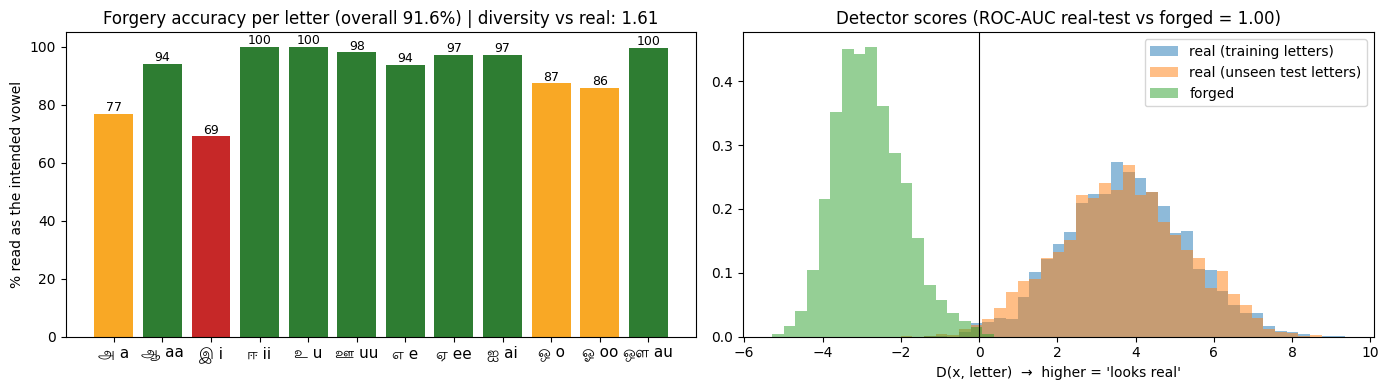

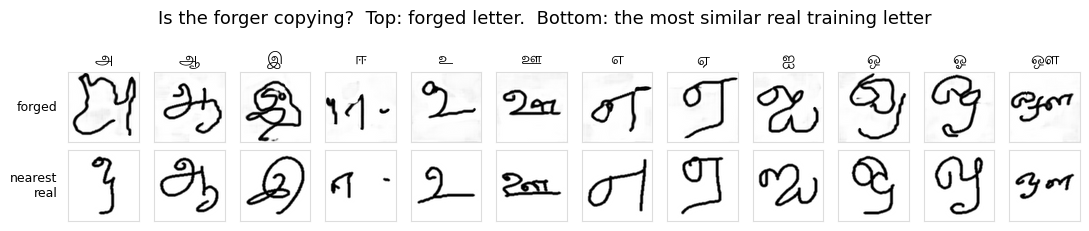

In [ ]:
# ============================================================== 6. JUDGE THE FORGER


def frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    covmean = linalg.sqrtm(s1 @ s2)
    covmean = covmean[0] if isinstance(covmean, tuple) else covmean
    covmean = covmean.real if np.iscomplexobj(covmean) else covmean
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))


seed_all(7)
n_eval = len(y_te)
lab_eval = np.random.permutation(np.resize(np.arange(N_CLS), n_eval))
forged_eval = forge(G_star, lab_eval)
p_forged = predict(model_real, forged_eval)
prob_forged = torch.softmax(torch.from_numpy(p_forged), 1).numpy()
forgery_acc_per_class = np.array([100 * (p_forged[lab_eval == v].argmax(1) == v).mean() for v in range(N_CLS)])
forgery_acc = 100 * float((p_forged.argmax(1) == lab_eval).mean())

f_test = predict(model_real, X_te, feats=True)
f_forged = predict(model_real, forged_eval, feats=True)
_sub = np.random.choice(len(X_tr), min(len(X_tr), n_eval), replace=False)
f_train = predict(model_real, X_tr[_sub], feats=True)
fd_forged = frechet(f_forged, f_test)
fd_real = frechet(f_train, f_test)


def intra_class_spread(f, labels, k=200):
    """Mean pairwise cosine distance between samples of the same letter, per letter."""
    fn = f / np.linalg.norm(f, axis=1, keepdims=True)
    out = []
    for v in range(N_CLS):
        g = fn[labels == v][:k]
        n = len(g)
        out.append(1 - ((g @ g.T).sum() - n) / (n * (n - 1)) if n > 1 else np.nan)
    return np.array(out)


div_ratio = float(np.nanmean(intra_class_spread(f_forged, lab_eval)) / np.nanmean(intra_class_spread(f_test, y_te)))

s_train = detector_scores(D, X_tr[_sub], y_tr[_sub])
s_test = detector_scores(D, X_te, y_te)
s_forged = detector_scores(D, forged_eval, lab_eval)
det_auc = float(roc_auc_score(np.r_[np.ones(len(s_test)), np.zeros(len(s_forged))], np.r_[s_test, s_forged]))
det_acc = 100 * float(((s_test > 0).sum() + (s_forged <= 0).sum()) / (len(s_test) + len(s_forged)))

print(f"Forgery accuracy (real-only recogniser reads the intended vowel): {forgery_acc:.1f}%")
print(f"Fréchet distance in recogniser features: forged vs real-test {fd_forged:.1f} | real-train vs real-test {fd_real:.1f} (floor)")
print(f"Diversity of forged letters relative to real handwriting: {div_ratio:.2f} (1.0 = as varied as real)")
print(f"Detector on unseen letters: ROC-AUC {det_auc:.3f} (0.5 = cannot tell) | accuracy at D=0: {det_acc:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
colors = ["#2e7d32" if a >= 90 else "#f9a825" if a >= 70 else "#c62828" for a in forgery_acc_per_class]
ax[0].bar(range(N_CLS), forgery_acc_per_class, color=colors)
ax[0].set_xticks(range(N_CLS)); ax[0].set_xticklabels([label(i) for i in range(N_CLS)], fontsize=11)
ax[0].set_ylim(0, 105); ax[0].set_ylabel("% read as the intended vowel")
ax[0].set_title(f"Forgery accuracy per letter (overall {forgery_acc:.1f}%) | diversity vs real: {div_ratio:.2f}")
for i, a in enumerate(forgery_acc_per_class):
    ax[0].text(i, a + 1, f"{a:.0f}", ha="center", fontsize=9)
bins = np.linspace(min(s_train.min(), s_test.min(), s_forged.min()), max(s_train.max(), s_test.max(), s_forged.max()), 50)
ax[1].hist(s_train, bins, alpha=0.5, density=True, label="real (training letters)")
ax[1].hist(s_test, bins, alpha=0.5, density=True, label="real (unseen test letters)")
ax[1].hist(s_forged, bins, alpha=0.5, density=True, label="forged")
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_title(f"Detector scores (ROC-AUC real-test vs forged = {det_auc:.2f})")
ax[1].set_xlabel("D(x, letter)  →  higher = 'looks real'"); ax[1].legend()
fig.tight_layout()
finish(fig, "07_forger_report_card.png")

# Memorisation check: nearest real training letter (cosine similarity in recogniser features)
f_tr_all = predict(model_real, X_tr, feats=True)
f_tr_n = f_tr_all / np.linalg.norm(f_tr_all, axis=1, keepdims=True)
pick_idx = [np.where(lab_eval == v)[0][0] for v in range(N_CLS)]
f_p = f_forged[pick_idx] / np.linalg.norm(f_forged[pick_idx], axis=1, keepdims=True)
sims = f_p @ f_tr_n.T
nn_idx = sims.argmax(1)
pair = np.stack([forged_eval[pick_idx], X_tr[nn_idx]])
letter_grid(pair, "Is the forger copying?  Top: forged letter.  Bottom: the most similar real training letter",
            "08_memorisation_check.png", col_titles=[label(i, False) for i in range(N_CLS)],
            row_titles=["forged", "nearest\nreal"])

## Stage 7 — Does forged data help the recogniser? (ablation)
Same architecture, same seed, same epochs, same 40 % test set; the only difference is whether forged letters are
added to the 60 % training set. With ~98–99 % already reached on real data, the gain can be small or zero; the
`best` preset repeats both runs with 3 seeds and reports mean ± std so the difference can be judged against noise.

Training the recogniser on REAL + FORGED letters (3714 real + 1800 forged)
  [real+forged seed 42] epoch  1/15 | train acc  76.93% | test acc  97.66%
  [real+forged seed 42] epoch  2/15 | train acc  98.20% | test acc  97.05%
  [real+forged seed 42] epoch  3/15 | train acc  98.69% | test acc  97.21%
  [real+forged seed 42] epoch  4/15 | train acc  99.09% | test acc  97.90%
  [real+forged seed 42] epoch  5/15 | train acc  99.27% | test acc  97.70%
  [real+forged seed 42] epoch  6/15 | train acc  99.49% | test acc  97.94%
  [real+forged seed 42] epoch  7/15 | train acc  99.69% | test acc  97.94%
  [real+forged seed 42] epoch  8/15 | train acc  99.67% | test acc  97.82%
  [real+forged seed 42] epoch  9/15 | train acc  99.82% | test acc  98.22%
  [real+forged seed 42] epoch 10/15 | train acc  99.96% | test acc  98.18%
  [real+forged seed 42] epoch 11/15 | train acc  99.95% | test acc  98.30%
  [real+forged seed 42] epoch 12/15 | train acc  99.93% | test acc  98.26%
  [real+forged seed 42] e

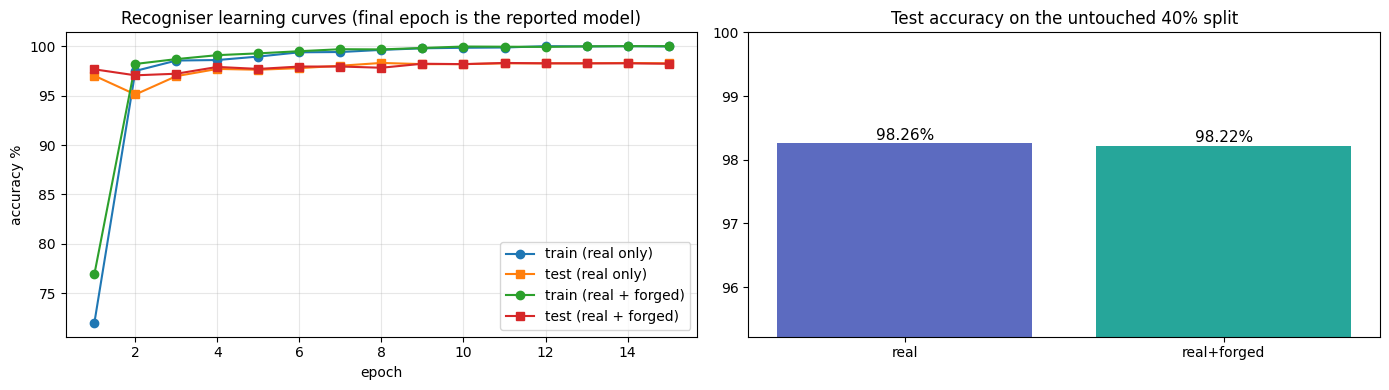

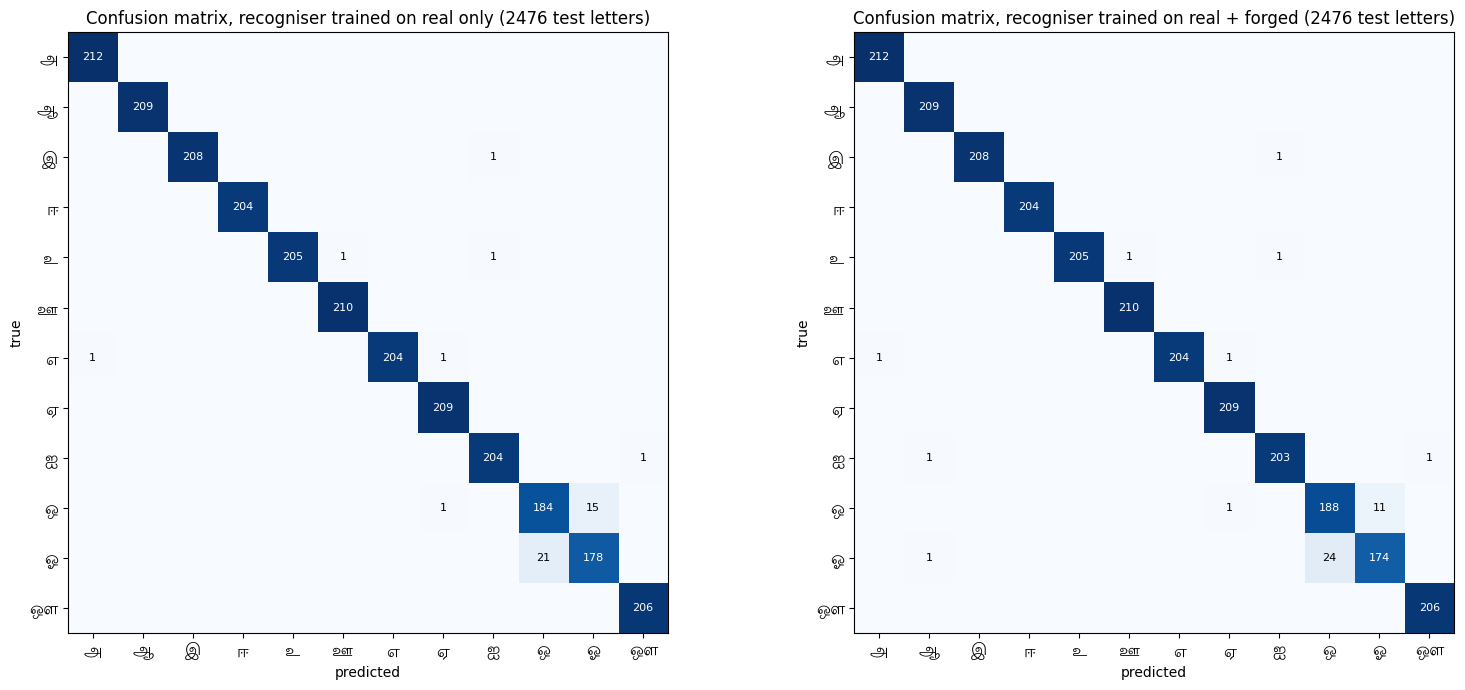


Classification report (real + forged, final epoch, seed 0):
              precision    recall  f1-score   support

       அ (a)      0.995     1.000     0.998       212
      ஆ (aa)      0.991     1.000     0.995       209
       இ (i)      1.000     0.995     0.998       209
      ஈ (ii)      1.000     1.000     1.000       204
       உ (u)      1.000     0.990     0.995       207
      ஊ (uu)      0.995     1.000     0.998       210
       எ (e)      1.000     0.990     0.995       206
      ஏ (ee)      0.991     1.000     0.995       209
      ஐ (ai)      0.990     0.990     0.990       205
       ஒ (o)      0.887     0.940     0.913       200
      ஓ (oo)      0.941     0.874     0.906       199
      ஔ (au)      0.995     1.000     0.998       206

    accuracy                          0.982      2476
   macro avg      0.982     0.982     0.982      2476
weighted avg      0.982     0.982     0.982      2476



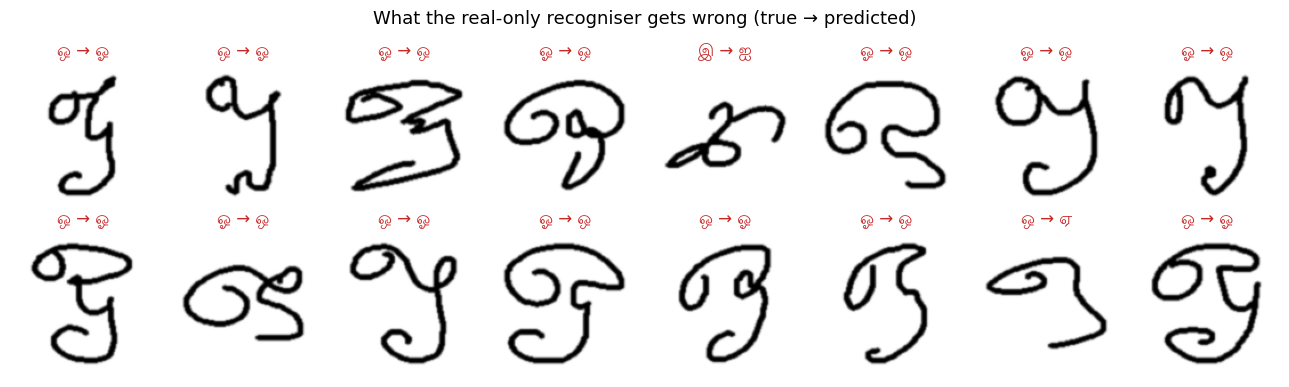

In [ ]:
# ============================================================== 7. ABLATION: REAL vs REAL + FORGED
seed_all(11)
lab_syn = np.repeat(np.arange(N_CLS), CFG["synth_per_class"])
X_syn = forge(G_star, lab_syn)
X_mix, y_mix = np.concatenate([X_tr, X_syn]), np.concatenate([y_tr, lab_syn])
print(f"Training the recogniser on REAL + FORGED letters ({len(y_tr)} real + {len(lab_syn)} forged)")
model_mix, hist_mix = train_recogniser(X_mix, y_mix, CFG["cls_epochs"], SEEDS[0], "real+forged")
m, pred_mix = evaluate(model_mix)
runs["real+forged"].append(m)
torch.save(model_mix.state_dict(), OUT / "recogniser_real_plus_forged.pt")
for s in SEEDS[1:]:
    for key, (Xs, ys) in {"real": (X_tr, y_tr), "real+forged": (X_mix, y_mix)}.items():
        mdl, _ = train_recogniser(Xs, ys, CFG["cls_epochs"], s, key)
        runs[key].append(evaluate(mdl)[0])
        del mdl


def mean_std(key, metric):
    v = np.array([r[metric] for r in runs[key]])
    return f"{v.mean():.2f} ± {v.std():.2f}" if len(v) > 1 else f"{v[0]:.2f}"


print(f"\n{'Training data':<16}{'Test accuracy %':>18}{'Macro-F1 %':>14}   (n seeds = {len(SEEDS)})")
for key in runs:
    print(f"{key:<16}{mean_std(key, 'acc'):>18}{mean_std(key, 'macro_f1'):>14}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ep = range(1, CFG["cls_epochs"] + 1)
for h, name in ((hist_real, "real only"), (hist_mix, "real + forged")):
    ax[0].plot(ep, h["train_acc"], marker="o", label=f"train ({name})")
    ax[0].plot(ep, h["test_acc"], marker="s", label=f"test ({name})")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy %"); ax[0].grid(alpha=0.3); ax[0].legend()
ax[0].set_title("Recogniser learning curves (final epoch is the reported model)")
names = list(runs)
means = [np.mean([r["acc"] for r in runs[k]]) for k in names]
stds = [np.std([r["acc"] for r in runs[k]]) for k in names]
ax[1].bar(names, means, yerr=stds if len(SEEDS) > 1 else None, color=["#5c6bc0", "#26a69a"], capsize=6)
lo = max(0, min(means) - 3)
ax[1].set_ylim(lo, 100)
for i, v in enumerate(means):
    ax[1].text(i, v + 0.05, f"{v:.2f}%", ha="center", fontsize=11)
ax[1].set_title(f"Test accuracy on the untouched {100 * len(y_te) / len(y_all):.0f}% split")
fig.tight_layout()
finish(fig, "10_recogniser_curves_and_ablation.png")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, pred, name in ((axes[0], pred_real, "real only"), (axes[1], pred_mix, "real + forged")):
    cm = confusion_matrix(y_te, pred, labels=range(N_CLS))
    ax.imshow(cm, cmap="Blues")
    for i in range(N_CLS):
        for j in range(N_CLS):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(N_CLS)); ax.set_yticks(range(N_CLS))
    ax.set_xticklabels([label(i, False) for i in range(N_CLS)], fontsize=12)
    ax.set_yticklabels([label(i, False) for i in range(N_CLS)], fontsize=12)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"Confusion matrix, recogniser trained on {name} ({len(y_te)} test letters)")
fig.tight_layout()
finish(fig, "11_confusion_matrices.png")

print("\nClassification report (real + forged, final epoch, seed 0):")
print(classification_report(y_te, pred_mix, target_names=[f"{UYIR[i]} ({ROMAN[i]})" for i in range(N_CLS)], digits=3,
                            zero_division=0))

wrong = np.where(pred_real != y_te)[0][:16]
if len(wrong):
    fig, axes = plt.subplots(2, 8, figsize=(13, 4), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(X_te[i], cmap="gray_r", vmin=0, vmax=255)
        ax.set_title(f"{label(y_te[i], False)} → {label(pred_real[i], False)}", fontsize=12, color="#c62828")
    fig.suptitle("What the real-only recogniser gets wrong (true → predicted)", fontsize=13)
    fig.tight_layout()
    finish(fig, "12_recogniser_mistakes.png")

## Stage 8 — Final showcase: the forger's letters and the detector's verdicts

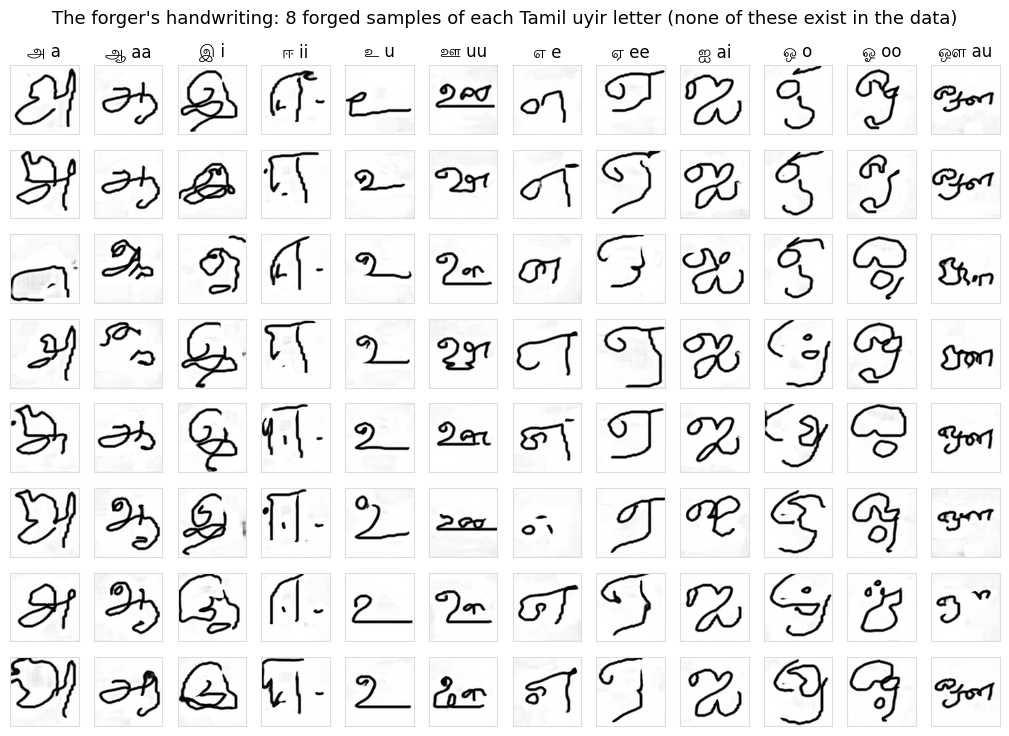

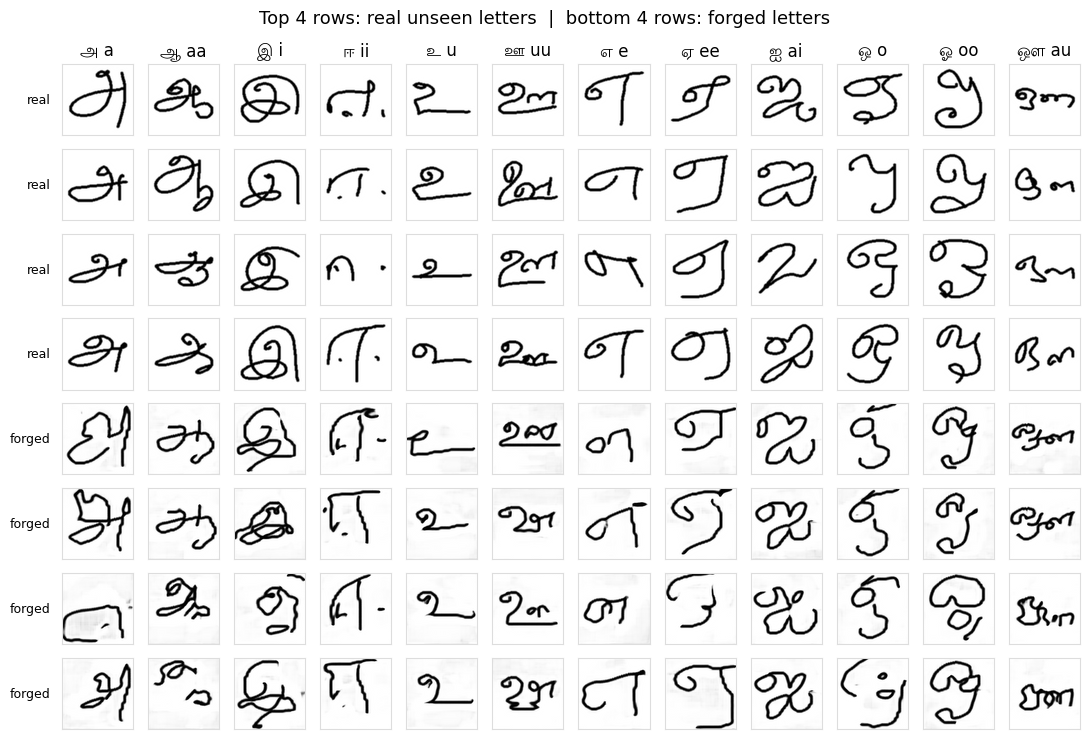

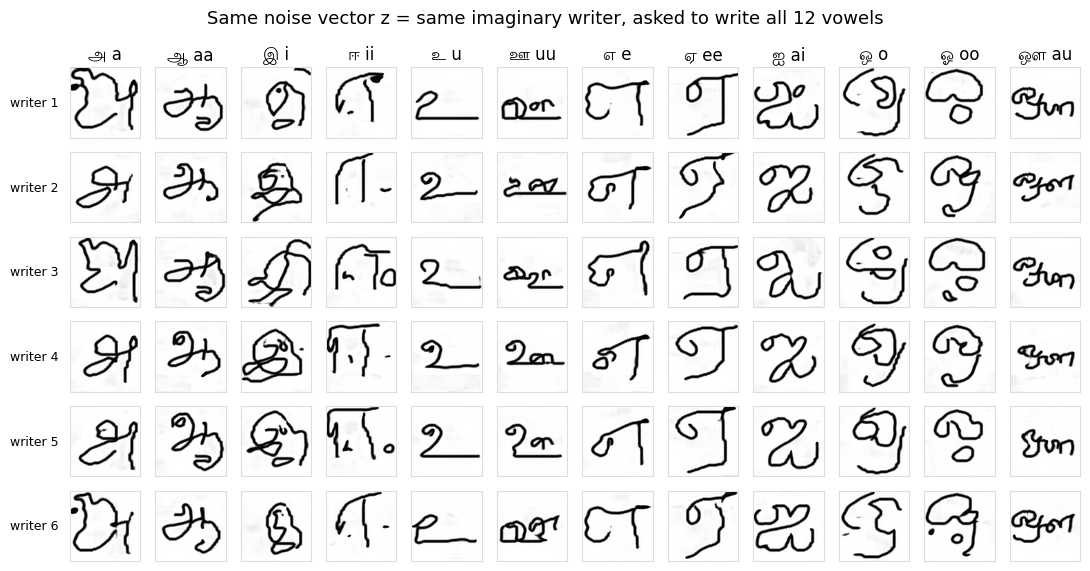

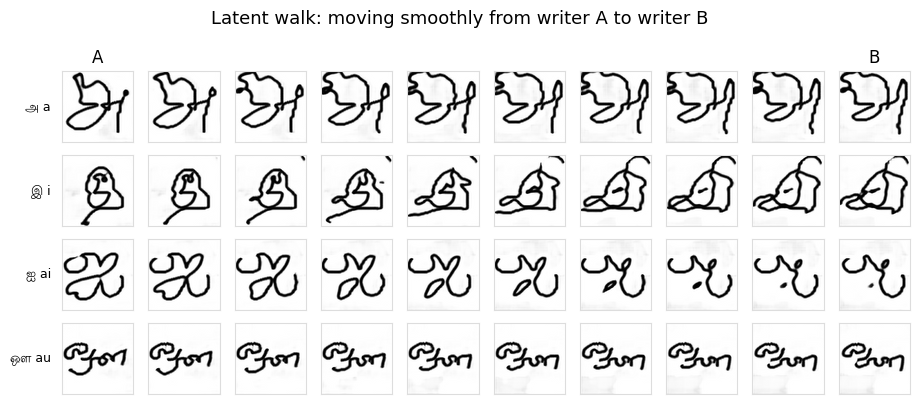

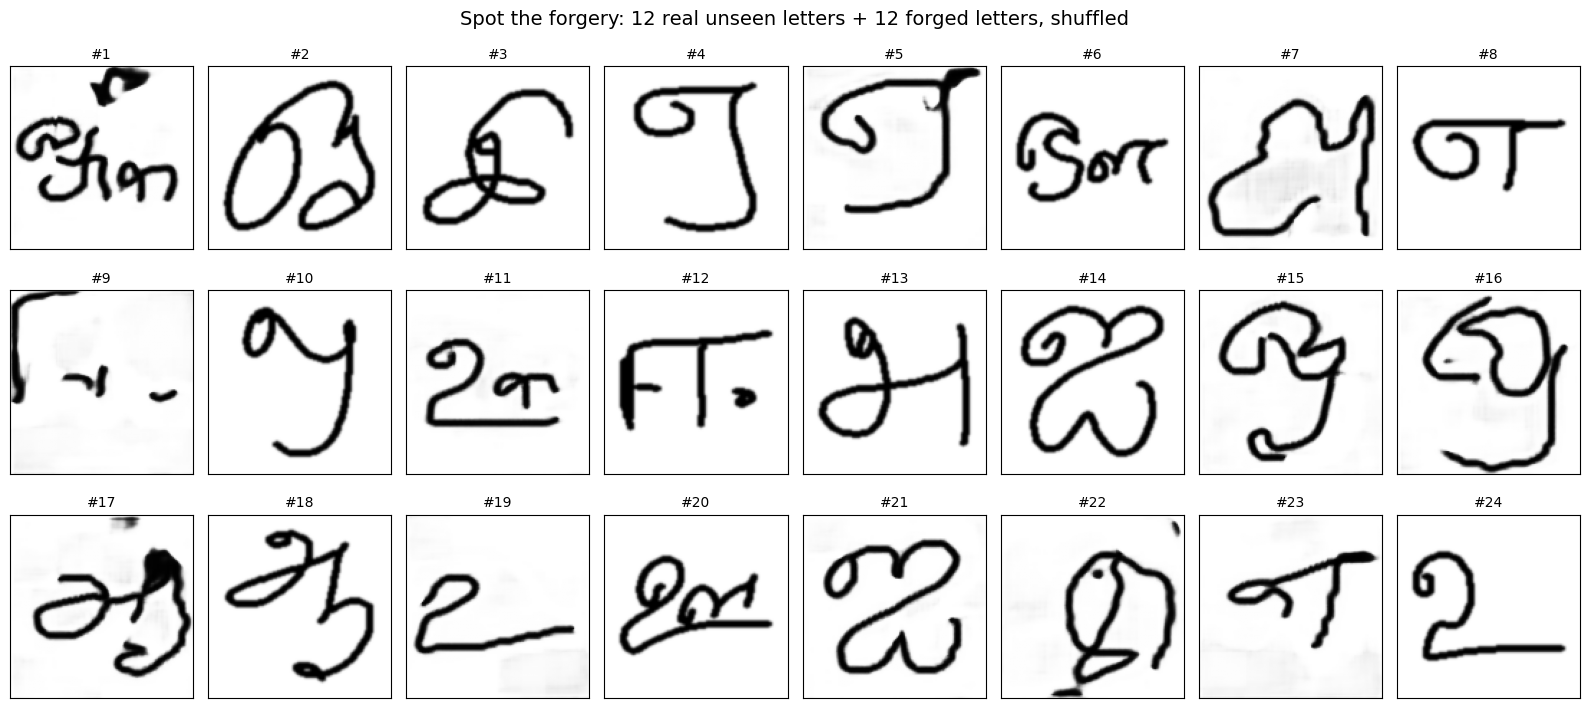

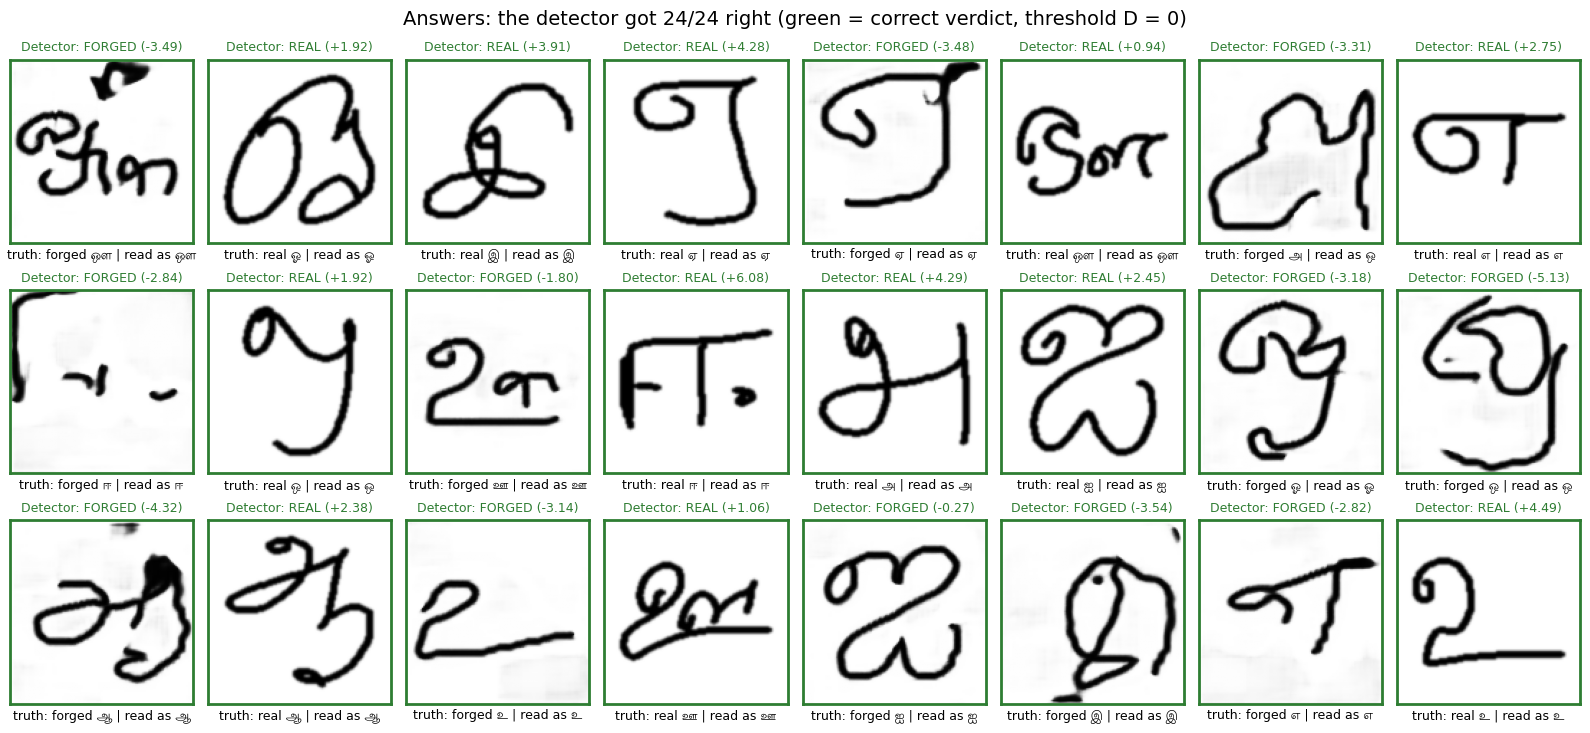

In [ ]:
# ============================================================== 8. FINAL SHOWCASE
seed_all(2026)
# 8a. Forged gallery next to real letters
n_rows = 8
gal_lab = np.tile(np.arange(N_CLS), n_rows)
gallery = forge(G_star, gal_lab).reshape(n_rows, N_CLS, IMG, IMG)
letter_grid(gallery, "The forger's handwriting: 8 forged samples of each Tamil uyir letter (none of these exist in the data)",
            "04_forged_gallery.png", col_titles=[label(i) for i in range(N_CLS)])
real_rows = np.stack([X_te[np.random.choice(np.where(y_te == v)[0], 4, replace=False)] for v in range(N_CLS)], 1)
compare = np.concatenate([real_rows, gallery[:4]])
letter_grid(compare, "Top 4 rows: real unseen letters  |  bottom 4 rows: forged letters",
            "04b_real_vs_forged.png", col_titles=[label(i) for i in range(N_CLS)],
            row_titles=["real"] * 4 + ["forged"] * 4)

# 8b. One "writer" (one noise vector) across all 12 letters
n_writers = 6
zw = torch.randn(n_writers, CFG["z_dim"]).repeat_interleave(N_CLS, 0)
style = forge(G_star, np.tile(np.arange(N_CLS), n_writers), z=zw).reshape(n_writers, N_CLS, IMG, IMG)
letter_grid(style, "Same noise vector z = same imaginary writer, asked to write all 12 vowels",
            "05_one_writer_all_letters.png", col_titles=[label(i) for i in range(N_CLS)],
            row_titles=[f"writer {i + 1}" for i in range(n_writers)])


# 8c. Latent walk: smooth change of handwriting between two writers
def slerp(a, b, t):
    a_n, b_n = a / a.norm(), b / b.norm()
    om = torch.acos((a_n * b_n).sum().clamp(-1, 1))
    return a if om.abs() < 1e-4 else (torch.sin((1 - t) * om) * a + torch.sin(t * om) * b) / torch.sin(om)


walk_letters = [0, 2, 8, 11]
steps = 10
za, zb = torch.randn(CFG["z_dim"]), torch.randn(CFG["z_dim"])
zs = torch.stack([slerp(za, zb, t) for t in np.linspace(0, 1, steps)])
walk = np.stack([forge(G_star, np.full(steps, v), z=zs) for v in walk_letters])
letter_grid(walk, "Latent walk: moving smoothly from writer A to writer B",
            "06_latent_walk.png", row_titles=[label(v) for v in walk_letters],
            col_titles=["A"] + [""] * (steps - 2) + ["B"])

# 8d. Spot the forgery: the detector's verdict on 12 real (unseen) + 12 forged letters
rng = np.random.default_rng(5)
real_pick = np.array([rng.choice(np.where(y_te == v)[0]) for v in range(N_CLS)])
fake_pick = forge(G_star, np.arange(N_CLS))
tiles = [(X_te[i], y_te[i], True) for i in real_pick] + [(fake_pick[v], v, False) for v in range(N_CLS)]
order = rng.permutation(len(tiles))
tiles = [tiles[i] for i in order]
scores = detector_scores(D, np.stack([t[0] for t in tiles]), np.array([t[1] for t in tiles]))
read = predict(model_real, np.stack([t[0] for t in tiles])).argmax(1)
for answers in (False, True):
    fig, axes = plt.subplots(3, 8, figsize=(16, 7.4))
    for k, (ax, (img, v, is_real), sc) in enumerate(zip(axes.flat, tiles, scores)):
        ax.imshow(img, cmap="gray_r", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if answers:
            says_real = sc > 0
            ok = says_real == is_real
            ax.set_title(f"Detector: {'REAL' if says_real else 'FORGED'} ({sc:+.2f})", fontsize=9,
                         color="#2e7d32" if ok else "#c62828")
            ax.set_xlabel(f"truth: {'real' if is_real else 'forged'} {label(v, False)} | read as {label(read[k], False)}",
                          fontsize=9)
            for s in ax.spines.values():
                s.set_color("#2e7d32" if ok else "#c62828"); s.set_linewidth(2)
        else:
            ax.set_title(f"#{k + 1}", fontsize=10)
    n_ok = sum(((sc > 0) == t[2]) for t, sc in zip(tiles, scores))
    fig.suptitle("Spot the forgery: 12 real unseen letters + 12 forged letters, shuffled" if not answers else
                 f"Answers: the detector got {n_ok}/24 right (green = correct verdict, threshold D = 0)", fontsize=14)
    fig.tight_layout()
    finish(fig, "09b_spot_the_forgery_answers.png" if answers else "09a_spot_the_forgery_question.png")

# 8e. Individual forged PNGs for slides
fl = OUT / "forged_letters"
shutil.rmtree(fl, ignore_errors=True)
per = 24
batch = forge(G_star, np.repeat(np.arange(N_CLS), per))
for v in range(N_CLS):
    d = fl / f"{v:02d}_{ROMAN[v]}"
    d.mkdir(parents=True, exist_ok=True)
    for k in range(per):
        Image.fromarray(255 - batch[v * per + k]).save(d / f"forged_{ROMAN[v]}_{k:02d}.png")

In [ ]:
# ============================================================== 9. RESULTS + DOWNLOAD
results = dict(
    preset=PRESET, split=SPLIT_MODE, arch=ARCH, n_train=int(len(y_tr)), n_test=int(len(y_te)),
    gan_iterations=int(TOTAL), seeds=SEEDS,
    recogniser={k: dict(acc=mean_std(k, "acc"), macro_f1=mean_std(k, "macro_f1"), runs=v) for k, v in runs.items()},
    forger=dict(forgery_accuracy=round(forgery_acc, 2),
                forgery_accuracy_per_letter={ROMAN[i]: round(float(a), 1) for i, a in enumerate(forgery_acc_per_class)},
                fd_forged_vs_real_test=round(fd_forged, 2), fd_real_train_vs_real_test=round(fd_real, 2),
                diversity_vs_real=round(div_ratio, 3)),
    detector=dict(roc_auc_real_test_vs_forged=round(det_auc, 3), accuracy_at_zero=round(det_acc, 2)),
)
(OUT / "results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")
md = [f"# Tamil uyir GAN results ({PRESET}, {SPLIT_MODE}, {ARCH})", "",
      f"Train letters: {len(y_tr)} | test letters: {len(y_te)} | GAN iterations: {TOTAL} | seeds: {len(SEEDS)}", "",
      "| Recogniser trained on | Test accuracy % | Macro-F1 % |", "|---|---|---|"]
md += [f"| {k} | {mean_std(k, 'acc')} | {mean_std(k, 'macro_f1')} |" for k in runs]
md += ["", "| Forger / detector metric | Value |", "|---|---|",
       f"| Forgery accuracy (real-only recogniser reads the intended vowel) | {forgery_acc:.1f}% |",
       f"| Fréchet distance, forged vs real test (recogniser features) | {fd_forged:.1f} |",
       f"| Fréchet distance, real train vs real test (floor) | {fd_real:.1f} |",
       f"| Diversity of forged letters vs real (1.0 = as varied as real) | {div_ratio:.2f} |",
       f"| Detector ROC-AUC, real test vs forged (0.5 = fooled) | {det_auc:.3f} |"]
(OUT / "results.md").write_text("\n".join(md), encoding="utf-8")
print("\n".join(md))

zip_path = BASE / "uyir_presentation_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(OUT.rglob("*")):
        if p.is_file() and (p.suffix in {".png", ".gif", ".json", ".md"} or p.name in {"forger_G_ema.pt", "detector_D.pt"}):
            zf.write(p, p.relative_to(OUT))
print(f"\nEverything is in {OUT}; figures + forged letters + forger/detector weights zipped to {zip_path}")
if IN_COLAB:
    try:
        from google.colab import files
        files.download(str(zip_path))
    except Exception as e:
        print("Download it from the Files panel:", e)

# Tamil uyir GAN results (standard, random_60_40, resnet)

Train letters: 3714 | test letters: 2476 | GAN iterations: 10000 | seeds: 1

| Recogniser trained on | Test accuracy % | Macro-F1 % |
|---|---|---|
| real | 98.26 | 98.21 |
| real+forged | 98.22 | 98.17 |

| Forger / detector metric | Value |
|---|---|
| Forgery accuracy (real-only recogniser reads the intended vowel) | 91.6% |
| Fréchet distance, forged vs real test (recogniser features) | 22.5 |
| Fréchet distance, real train vs real test (floor) | 1.2 |
| Diversity of forged letters vs real (1.0 = as varied as real) | 1.61 |
| Detector ROC-AUC, real test vs forged (0.5 = fooled) | 1.000 |

Everything is in /content/uyir_outputs; figures + forged letters + forger/detector weights zipped to /content/uyir_presentation_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>